# DONE WITH AI WITHOUT CHECKING FOR MISTAKES ETC BUT THE FINDINGS ARE RELEVANT MENTIONING
# Selection-bias check: who did we leave out?

**Question (from the TA feedback):** our analysis only uses people with complete bloodwork and covariates.
Are the people we dropped different from the people we kept? If yes, our results might not apply to everyone.

**Approach:** take all adults who answered the heart-disease question (the step before any blood or covariate exclusions),
split them into three groups, and compare them:

1. **Included**: the analytic sample everyone uses
2. **Excluded: no bloodwork**: NLR or hs-CRP missing
3. **Excluded: missing covariates**: had bloodwork, but e.g. income or BMI missing

Two parts: a **comparison table with p-values** (for Appendix B) and a **logistic regression** that asks which characteristics make someone more likely to be missing bloodwork (forest plot).

Uses the shared `prepare_data.py` functions, so nothing about the cohort is redefined.
This is purely descriptive, so using all participants including the test set is fine.

In [11]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from matplotlib.ticker import NullFormatter
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepare_data.py").exists())
sys.path.insert(0, str(ROOT))
from prepare_data import load_data, build_analysis_variables, CONFIG

# everyone, with the same analysis variables the group uses
everyone = build_analysis_variables(load_data("clean"))

# adults who answered the heart-disease question = flowchart step before the blood/covariate exclusions
adults = everyone[(everyone["age"] >= CONFIG["min_age"]) & everyone["chd_mi"].notna()].copy()

analytic = load_data()
GROUPS = ["Included", "Excluded: no bloodwork", "Excluded: missing covariates"]
adults["group"] = np.select(
    [adults["SEQN"].isin(analytic["SEQN"]), adults["nlr"].isna() | adults["crp"].isna()],
    GROUPS[:2], default=GROUPS[2],
)
adults["group"].value_counts().reindex(GROUPS)

group
Included                        4544
Excluded: no bloodwork          2235
Excluded: missing covariates     994
Name: count, dtype: int64

## 1. Why were people excluded?

`exam_status` = 1 means the person only did the home interview and never came to the examination centre, so no blood was ever taken.

In [12]:
reason = pd.crosstab(adults["group"], adults["exam_status"].map({1: "interview only", 2: "interview + exam"}))
display(reason.reindex(GROUPS))

# among people with bloodwork but missing covariates: which covariate was missing?
missing_cov = adults[adults["group"] == GROUPS[2]]
missing_cov[["income_pir", "egfr", "hypertension", "total_chol", "bmi", "lipid_med", "smoking"]].isna().sum().sort_values(ascending=False)

exam_status,interview + exam,interview only
group,,
Included,4544,0
Excluded: no bloodwork,499,1736
Excluded: missing covariates,994,0


income_pir      706
egfr            151
hypertension    107
total_chol       96
bmi              74
lipid_med        24
smoking           7
dtype: int64

## 2. Comparison table with p-values (for Appendix B)

Mean (SD) for numbers, % for categories. Each excluded group is tested against the included people:
- **t-test** (Welch) for age and income
- **chi-square test** for yes/no and category variables (one p-value per variable, e.g. one for all of race/ethnicity)

Only variables that exist for all three groups are shown (people without an exam have no BMI or blood pressure).
Note: with thousands of people, even small differences give small p-values, so look at the percentages too.

In [13]:
included = adults[adults["group"] == GROUPS[0]]

def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def p_ttest(var, other):
    return stats.ttest_ind(included[var].dropna(), other[var].dropna(), equal_var=False).pvalue

def p_chi2(var, other):
    both = pd.concat([included, other])
    return stats.chi2_contingency(pd.crosstab(both["group"], both[var]))[1]

def mean_sd(df, var):
    return f"{df[var].mean():.1f} ({df[var].std():.1f})"

def pct(df, var, value=1):
    x = df[var].dropna()
    return f"{100 * (x == value).mean():.1f}%"

RACE = {"nh_white": "Non-Hispanic White", "nh_black": "Non-Hispanic Black", "mexican_american": "Mexican American",
        "other_hispanic": "Other Hispanic", "nh_asian": "Non-Hispanic Asian", "other_multi": "Other / multiracial"}
SMOKING = {"never": "Never", "former": "Former", "current": "Current"}
INDENT = "\u2003\u2003"   # two wide spaces, so sub-rows show indented

columns = {}
for g in GROUPS:
    df = adults[adults["group"] == g]
    col = {"Age, years": mean_sd(df, "age"), "Male sex": pct(df, "male"),
           "Income-to-poverty ratio": mean_sd(df, "income_pir"), "Race/ethnicity": ""}
    col.update({INDENT + label: pct(df, "race_eth", code_) for code_, label in RACE.items()})
    col["Smoking"] = ""
    col.update({INDENT + label: pct(df, "smoking", code_) for code_, label in SMOKING.items()})
    col.update({"Diabetes": pct(df, "diabetes"), "Lipid-lowering medication": pct(df, "lipid_med"),
                "CHD/MI (outcome)": pct(df, "chd_mi")})
    columns[f"{g.replace('Excluded: ', '').capitalize()} (n={len(df):,})"] = col

    if g != GROUPS[0]:
        columns[f"p vs included ({g.replace('Excluded: ', '')})"] = {
            "Age, years": fmt_p(p_ttest("age", df)), "Male sex": fmt_p(p_chi2("male", df)),
            "Income-to-poverty ratio": fmt_p(p_ttest("income_pir", df)), "Race/ethnicity": fmt_p(p_chi2("race_eth", df)),
            "Smoking": fmt_p(p_chi2("smoking", df)), "Diabetes": fmt_p(p_chi2("diabetes", df)),
            "Lipid-lowering medication": fmt_p(p_chi2("lipid_med", df)), "CHD/MI (outcome)": fmt_p(p_chi2("chd_mi", df)),
        }

table = pd.DataFrame(columns).fillna("")
table.style.set_properties(**{"text-align": "left"})

,"Included (n=4,544)","No bloodwork (n=2,235)",p vs included (no bloodwork),Missing covariates (n=994),p vs included (missing covariates)
"Age, years",53.9 (16.8),52.7 (18.6),0.010,53.8 (18.2),0.771
Male sex,44.9%,43.4%,0.278,45.8%,0.629
Income-to-poverty ratio,3.0 (1.6),2.7 (1.7),<0.001,2.4 (1.7),<0.001
Race/ethnicity,,,<0.001,,<0.001
Non-Hispanic White,61.5%,55.1%,,51.1%,
Non-Hispanic Black,10.8%,15.5%,,15.6%,
Mexican American,6.5%,7.6%,,7.8%,
Other Hispanic,9.7%,9.2%,,13.1%,
Non-Hispanic Asian,5.4%,5.2%,,6.1%,
Other / multiracial,6.2%,7.3%,,6.2%,


## 3. Who is more likely to be missing bloodwork? (logistic regression)

One model, outcome = **no bloodwork (1) vs. included (0)**, with all characteristics at once.
The result is an **odds ratio (OR)** per characteristic:
- **OR > 1**: more likely to be missing bloodwork, **OR < 1**: less likely
- if the **95% confidence interval crosses 1**, there's no clear difference

Because everything is in one model, each OR is adjusted for the others (e.g. ethnicity is compared at the same income).
People with missing income can't go into the model, so they are dropped automatically.
The "missing covariates" group isn't modelled: they were excluded mostly *because* income is missing, so income can't be used to predict it.

In [14]:
model_data = adults[adults["group"].isin(GROUPS[:2])].copy()
model_data["no_bloodwork"] = (model_data["group"] == GROUPS[1]).astype(int)
model_data["age_per_10y"] = model_data["age"] / 10

formula = ("no_bloodwork ~ age_per_10y + male + C(race_eth, Treatment('nh_white')) + income_pir"
           " + C(smoking, Treatment('never')) + diabetes + lipid_med + chd_mi")
model = smf.logit(formula, data=model_data).fit(disp=0)
print(f"People in the model: {int(model.nobs):,} of {len(model_data):,} "
      f"({len(model_data) - int(model.nobs)} dropped because of missing income etc.)")

LABELS = {
    "age_per_10y": "Age (per 10 years)",
    "male": "Male sex",
    "C(race_eth, Treatment('nh_white'))[T.nh_black]": "Non-Hispanic Black (vs. White)",
    "C(race_eth, Treatment('nh_white'))[T.mexican_american]": "Mexican American (vs. White)",
    "C(race_eth, Treatment('nh_white'))[T.other_hispanic]": "Other Hispanic (vs. White)",
    "C(race_eth, Treatment('nh_white'))[T.nh_asian]": "Non-Hispanic Asian (vs. White)",
    "C(race_eth, Treatment('nh_white'))[T.other_multi]": "Other / multiracial (vs. White)",
    "income_pir": "Income-to-poverty ratio (per 1 unit)",
    "C(smoking, Treatment('never'))[T.former]": "Former smoker (vs. never)",
    "C(smoking, Treatment('never'))[T.current]": "Current smoker (vs. never)",
    "diabetes": "Diabetes",
    "lipid_med": "Lipid-lowering medication",
    "chd_mi": "CHD/MI (outcome)",
}
ci = np.exp(model.conf_int())
ors = pd.DataFrame({"OR": np.exp(model.params), "CI low": ci[0], "CI high": ci[1], "p": model.pvalues}).loc[list(LABELS)]
ors.index = list(LABELS.values())
ors.style.format({"OR": "{:.2f}", "CI low": "{:.2f}", "CI high": "{:.2f}", "p": fmt_p})

People in the model: 6,166 of 6,779 (613 dropped because of missing income etc.)


,OR,CI low,CI high,p
Age (per 10 years),0.98,0.94,1.02,0.291
Male sex,0.95,0.85,1.07,0.433
Non-Hispanic Black (vs. White),1.33,1.11,1.59,0.002
Mexican American (vs. White),0.98,0.77,1.25,0.879
Other Hispanic (vs. White),0.85,0.69,1.05,0.123
Non-Hispanic Asian (vs. White),0.89,0.67,1.17,0.389
Other / multiracial (vs. White),1.14,0.91,1.44,0.258
Income-to-poverty ratio (per 1 unit),0.91,0.88,0.95,<0.001
Former smoker (vs. never),1.07,0.93,1.23,0.375
Current smoker (vs. never),1.08,0.91,1.27,0.367


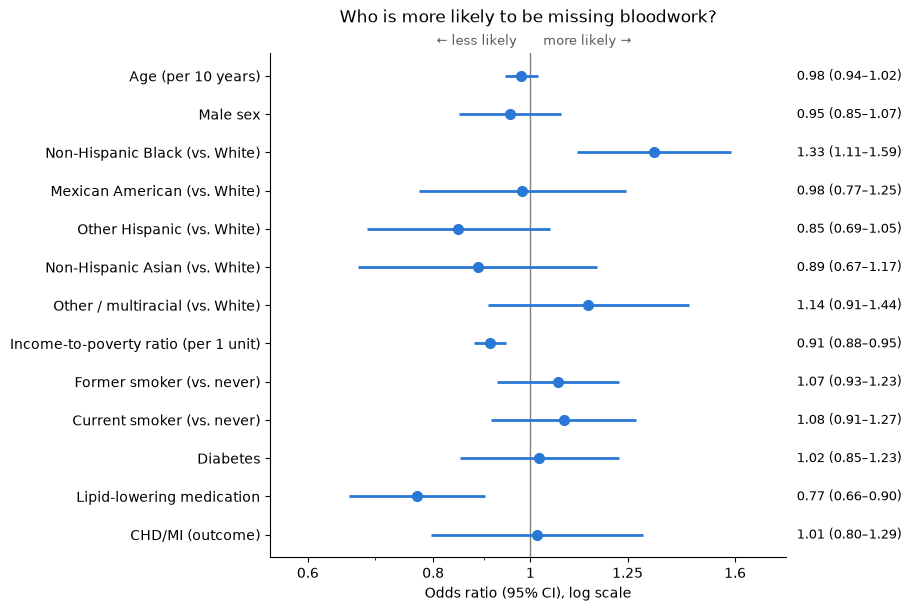

In [15]:
y = np.arange(len(ors))
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.axvline(1, color="0.5", linewidth=1)
ax.errorbar(ors["OR"], y, xerr=[ors["OR"] - ors["CI low"], ors["CI high"] - ors["OR"]],
            fmt="o", color="#2a78d6", elinewidth=2, markersize=7, capsize=0)

ax.set_xscale("log")
ax.set_xlim(0.55, 1.8)
ax.set_xticks([0.6, 0.8, 1, 1.25, 1.6], ["0.6", "0.8", "1", "1.25", "1.6"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(y, ors.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio (95% CI), log scale")
ax.set_title("Who is more likely to be missing bloodwork?", pad=22)

# direction hints above the plot, and the numbers on the right
top = ax.get_xaxis_transform()
ax.text(0.97, 1.01, "\u2190 less likely", transform=top, ha="right", va="bottom", fontsize=9, color="0.35")
ax.text(1.03, 1.01, "more likely \u2192", transform=top, ha="left", va="bottom", fontsize=9, color="0.35")
right = ax.get_yaxis_transform()
for yi, (o, lo, hi) in enumerate(ors[["OR", "CI low", "CI high"]].values):
    ax.text(1.02, yi, f"{o:.2f} ({lo:.2f}\u2013{hi:.2f})", transform=right, va="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. What it means

*(numbers as of the default CONFIG, 30.10.)*

- **Why people were dropped:** 2,235 of the 3,229 excluded adults have no bloodwork, and about 78% of those only did the home interview and never came to the exam centre. The other 994 had bloodwork but were missing a covariate, mostly income.
- **The same in all groups:** the heart-disease rate (7.4% included vs. 6.6% and 7.5%, p = 0.23 and 0.94; in the model OR 1.01, 95% CI 0.80–1.29), and also sex, smoking and diabetes. So being excluded is **not linked to having heart disease**.
- **Different:**
  - Excluded people have **lower income** (p < 0.001 in both groups). In the model, each 1-unit higher income-to-poverty ratio means about 9% lower odds of missing bloodwork (OR 0.91, 0.88–0.95).
  - **Non-Hispanic Black** participants are more often excluded (15.5% vs. 10.8%), even at the same income (OR 1.33, 1.11–1.59).
  - People on **cholesterol medication** are less often missing bloodwork (23% vs. 29%; OR 0.77, 0.66–0.90).
- **Age** is a nice example of "significant but irrelevant": p = 0.010 in the table, but the difference is only 1.2 years, and it disappears in the model (OR 0.98, 0.94–1.02).
- **For the report:** our analytic sample slightly over-represents wealthier, White and medically treated participants. Since income and ethnicity are covariates in our main models, this mainly limits **generalisability** rather than distorting the adjusted association. We can't check whether the excluded people's *markers* differ, because those are exactly what's missing. Multiple imputation could bring back the 994 people with bloodwork; it can't help the people who have no bloodwork at all.
